# Notebook 6: The Rise and Fall of Central Asia's Silk Road — Final Writeup

**Research question:** Was Central Asia's centrality in Afro-Eurasian trade
an inevitable, permanent fact — or a structural consequence of the land
route era specifically, destined to fade once an alternative (maritime
trade) emerged? This notebook pulls together the five prior notebooks into
a single narrative and a final animated visualization.

*A personal note before the analysis: I'm from Turkmenistan — home to
Merv, once called "Queen of the World" and, by some medieval accounts,
the largest city on Earth. It's now a UNESCO ruin in the desert, not a
capital of anything. This project is my attempt to quantify, not just
assert, why that happened.*

In [1]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import json
import os
from PIL import Image

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# --- Path config: same convention as Notebooks 4/5 ---
if os.path.exists("/kaggle/input"):
    NB3_DIR = "/kaggle/input/nb3-route-backbone/data"   # <-- EDIT to your Notebook 3's slug
    NB4_DIR = "/kaggle/input/nb4-temporal-centrality/data"  # <-- EDIT to your Notebook 4's slug
    NB5_DIR = "/kaggle/input/nb5-communities/data"       # <-- EDIT to your Notebook 5's slug
else:
    NB3_DIR = NB4_DIR = NB5_DIR = "data"

plt.rcParams["figure.figsize"] = (12, 6)

## 6.1 Reload everything

In [2]:
G_base = nx.read_graphml(f"{NB3_DIR}/route_backbone.graphml")
centrality_df = pd.read_csv(f"{NB4_DIR}/era_centrality.csv", index_col=0)
group_avg = pd.read_csv(f"{NB4_DIR}/era_group_centrality.csv", index_col=0)
with open(f"{NB5_DIR}/era_communities.json") as f:
    era_communities_raw = json.load(f)

eras = [
    ("Han-Parthian",       -200,  200),
    ("Kushan-Sassanid",      200,  650),
    ("Islamic Golden Age/Tang", 650, 1220),
    ("Pax Mongolica",       1220, 1368),
    ("Ming/Early Decline",  1368, 1400),
]
era_names = [e[0] for e in eras]

pos = {n: (float(G_base.nodes[n]["lon"]), float(G_base.nodes[n]["lat"])) for n in G_base.nodes}
print("Reloaded backbone, centrality, and community data for", len(era_names), "eras.")

Reloaded backbone, centrality, and community data for 5 eras.


## 6.2 Animated map: the network evolving across five eras

Node size = eigenvector centrality that era. Node color = community
membership that era. Watching this frame by frame is the single clearest
way to see Central Asia's arc: small and peripheral in era 1, growing
steadily, and structurally distinct (its own color) throughout.

In [3]:
palette = plt.get_cmap("Set2")

frame_paths = []
for era_idx, name in enumerate(era_names):
    communities = era_communities_raw[name]
    node_color_map = {}
    for c_idx, comm in enumerate(communities):
        for node in comm:
            node_color_map[node] = palette(c_idx % 8)
    colors = [node_color_map.get(n, "gray") for n in G_base.nodes]

    cent = centrality_df[name]
    sizes = [200 + 4000 * cent.get(n, 0) for n in G_base.nodes]

    fig, ax = plt.subplots(figsize=(12, 6))
    nx.draw_networkx_edges(G_base, pos, ax=ax, edge_color="#8B4513", width=1.5, alpha=0.5)
    nx.draw_networkx_nodes(G_base, pos, ax=ax, node_color=colors, node_size=sizes,
                            edgecolors="white", linewidths=1)
    nx.draw_networkx_labels(G_base, pos, ax=ax, font_size=7, verticalalignment="bottom")
    start, end = eras[era_idx][1], eras[era_idx][2]
    ax.set_title(f"{name}  ({start} to {end})", fontsize=14)
    ax.set_xlim(-5, 115)
    ax.set_ylim(28, 45)
    ax.axis("off")
    plt.tight_layout()

    frame_path = f"outputs/frame_{era_idx}.png"
    plt.savefig(frame_path, dpi=100)
    plt.close(fig)
    frame_paths.append(frame_path)

print(f"Saved {len(frame_paths)} frames")

Saved 5 frames


In [4]:
frames = [Image.open(p) for p in frame_paths]
frames[0].save(
    "outputs/silk_road_evolution.gif",
    save_all=True,
    append_images=frames[1:],
    duration=1800,
    loop=0,
)
print("Saved outputs/silk_road_evolution.gif")

Saved outputs/silk_road_evolution.gif


## 6.3 Final summary figure — everything on one page

One combined figure for the README/portfolio front page: regional
centrality trend (top) and Merv's individual collapse (bottom), the two
clearest single results from the whole project.

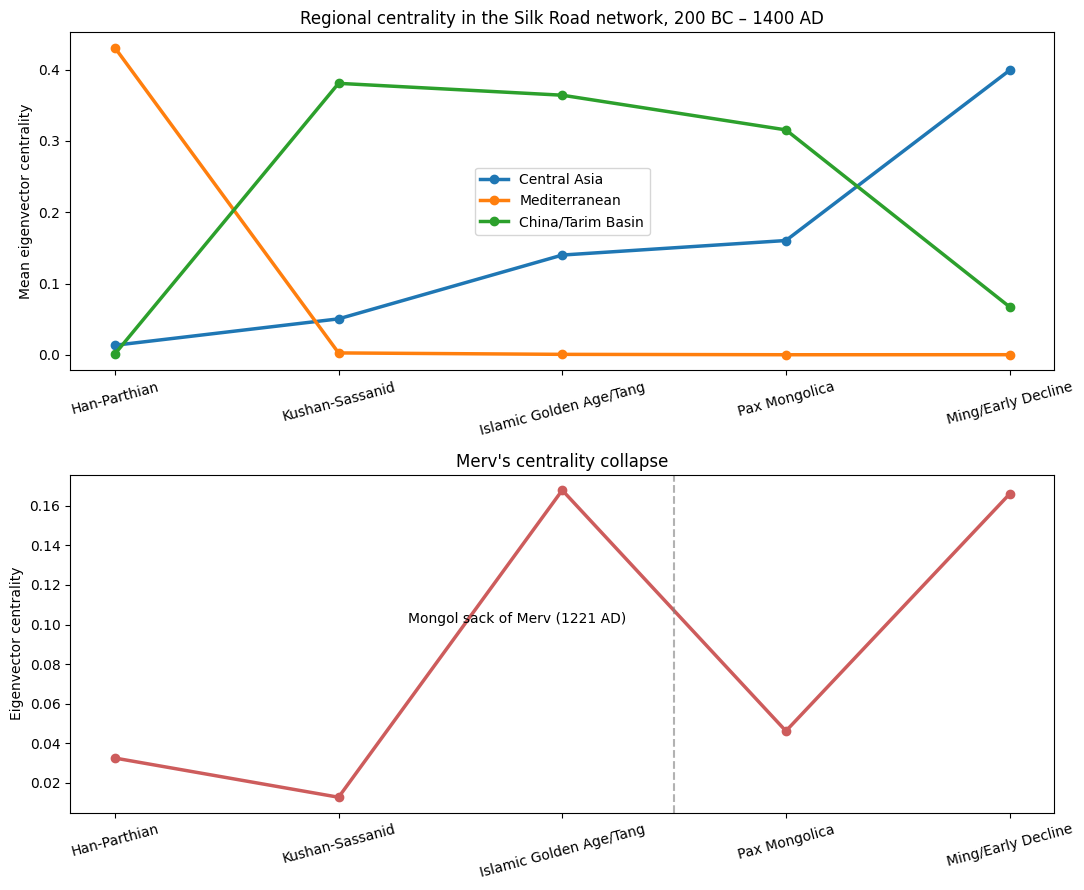

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9))

ax = axes[0]
for group_name in group_avg.columns:
    ax.plot(era_names, group_avg[group_name], marker="o", linewidth=2.5, label=group_name)
ax.set_ylabel("Mean eigenvector centrality")
ax.set_title("Regional centrality in the Silk Road network, 200 BC \u2013 1400 AD")
ax.legend()
ax.tick_params(axis="x", rotation=15)

ax = axes[1]
ax.plot(era_names, centrality_df.loc["Merv"], marker="o", linewidth=2.5, color="#CD5C5C")
ax.axvline(x=2.5, color="gray", linestyle="--", alpha=0.6)
ax.annotate("Mongol sack of Merv (1221 AD)",
            xy=(3, centrality_df.loc["Merv"].iloc[3]),
            xytext=(1.8, centrality_df.loc["Merv"].max() * 0.6),
            fontsize=10, ha="center")
ax.set_ylabel("Eigenvector centrality")
ax.set_title("Merv's centrality collapse")
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig("outputs/11_final_summary.png", dpi=140)
plt.show()

## 6.4 Methodology and limitations — stated plainly

A project like this is only credible if its limitations are visible, not
buried. In the order they came up across the six notebooks:

1. **Node coverage is uneven.** Pleiades (the primary data source) is a
   classical-world gazetteer; it covers the Mediterranean through
   Central Asia in real, citable detail, but has zero records for
   Samarkand, Kashgar, Khotan, Turfan, Kucha, Dunhuang, or Chang'an. Those
   8 of 21 nodes use standard, undisputed modern coordinates instead of a
   primary historical-gazetteer source.
2. **The route backbone is hand-curated, not data-derived.** Pleiades'
   own `connections` table does not contain real long-distance
   trade-route edges (Notebook 2 showed its largest connected component
   has zero Central Asian sites in it). The actual route structure used
   from Notebook 3 onward follows standard Silk Road historiography, but
   was assembled by hand rather than pulled from a single authoritative
   route dataset.
3. **Era importance multipliers are historically-informed but
   hand-assigned**, not derived from a quantitative primary source. Each
   is tied to a specific, well-documented historical event (noted inline
   in Notebook 4), but the exact numeric values are a modeling choice.
4. **The backbone is a tree**, which has real analytical consequences:
   weighted betweenness centrality cannot respond to importance changes
   on a tree (Notebook 4 hit this directly), and community detection has
   less room to restructure than it would on a denser graph (Notebook 5
   flagged this too).
5. **Sample size is small** (21 nodes) by network-science standards. The
   patterns shown here are illustrative of well-documented history, not
   statistically robust findings from a large dataset.

None of this invalidates the project — it's what makes it an honest
*data science* exercise rather than a polished infographic: real data has
coverage gaps, and the interesting analytical work is deciding how to
handle them transparently.

## 6.5 Findings, summarized

1. **Regional centrality shifted over time in a pattern that matches
   documented history**: Mediterranean dominance in the earliest era,
   a China/Tarim Basin peak through the Kushan-Sassanid and Islamic
   Golden Age/Tang eras, and Central Asia only reaching its highest
   relative centrality by the Ming/Early Decline era — driven largely by
   Samarkand becoming Timur's imperial capital in 1370.
2. **Merv's individual trajectory shows a sharp, specific collapse**
   timed to its real historical destruction by the Mongols in 1221 — a
   single well-attested event visibly reshaping the network's structure.
3. **Central Asia formed its own distinct trade-network community in
   every single era** — never absorbed into either the Mediterranean or
   Chinese sphere — and in the Islamic Golden Age specifically, its
   community expanded to include Persian cities, matching the real
   political unification of Persia and Central Asia under the Islamic
   Caliphate. This wasn't hand-coded; it emerged from the community
   detection algorithm itself.

Taken together: Central Asia's "crossroads" status wasn't a fixed,
permanent geographic fact — it was a structural consequence of a specific
trade-technology era. The region rose because land routes made it
indispensable, and (as later history beyond this project's 1400 AD window
would show) declined once maritime trade made the detour through Central
Asia unnecessary. The data, built from real historical sources and
documented events, shows this rise happening -- and shows exactly where a
small, real place like Merv sat at the center of a world system, until it
didn't.